<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Recomendaciones a partir de un artículo</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Qué leer después de un artículo, usando solo los enlaces.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Los notebooks anteriores dicen qué es importante en general o dentro de un tema. Aquí preguntamos algo más concreto: **si alguien está leyendo este artículo, ¿qué le recomendamos?**

Damos 10 recomendaciones por artículo. Cada una se elige con los puntajes de los 6.88 millones de artículos, sin recortar candidatos.

Usamos solo los enlaces. No usamos el texto de los artículos ni datos de lectores, porque el dump no trae visitas ni clics. Por eso podemos medir si las recomendaciones están relacionadas con el artículo, pero no si a un lector le sirven.

In [1]:
# Librerías, rutas, paleta y funciones auxiliares de estilo
import re
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import scipy.sparse as sp
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from IPython.display import display

sys.path.insert(0, "..")   # registro.py está en la carpeta Wikipedia/
import registro as reg

NB = "04_recomendaciones"  # carpeta de resultados: data/resultados/04_recomendaciones/

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 220)

GRAFO = Path("..") / "data" / "grafo"
TOPICOS_DIR = Path("..") / "data" / "resultados" / "03_topic_sensitive"
BETA = 0.85
K_RECOMENDACIONES = 10

AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, TINTA = "#8C8C8C", "#333333"
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    """Aplica el estilo común a unos ejes de matplotlib."""
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Datos</span></div>

Cargamos la matriz del notebook 2, sin páginas de desambiguación, y su PageRank general $r$.

In [2]:
# Carga de la matriz, grafo de análisis y PageRank general
inicio = time.time()
A = sp.load_npz(GRAFO / "adyacencia.npz")
nodos = pq.read_table(GRAFO / "nodos", columns=["id", "idx", "title", "is_disambig"]).to_pandas().sort_values("idx").reset_index(drop=True)
conserva = ~nodos["is_disambig"].to_numpy()
A_an = A[conserva][:, conserva].tocsr()
del A
nodos_an = nodos[conserva].reset_index(drop=True)
n = len(nodos_an)
k_out = np.asarray(A_an.sum(axis=1)).ravel()
k_in = np.asarray(A_an.sum(axis=0)).ravel()
inv_k_out = np.divide(1.0, k_out, out=np.zeros(n), where=k_out > 0)
titulos = nodos_an["title"].to_numpy()
posicion_titulo = pd.Series(np.arange(n), index=nodos_an["title"]).groupby(level=0).first()

puntajes = pd.read_parquet(GRAFO / "puntajes.parquet")
assert np.array_equal(puntajes["id"].to_numpy(), nodos_an["id"].to_numpy())
pr_general = puntajes["pagerank"].to_numpy()
lugar_general = pd.Series(pr_general).rank(ascending=False, method="min").astype(int).to_numpy()

BLOQUES = 16
POOL = ThreadPoolExecutor(BLOQUES)


def partir(X, bloques=BLOQUES):
    """Divide una matriz CSR en bloques consecutivos de filas (ver notebook 2)."""
    cortes = np.linspace(0, X.shape[0], bloques + 1).astype(int)
    return [X[a:b] for a, b in zip(cortes[:-1], cortes[1:])]


def producto(bloques, x):
    """Calcula X @ x multiplicando en paralelo los bloques de filas de X (ver notebook 2)."""
    return np.concatenate(list(POOL.map(lambda bloque: bloque @ x, bloques)))


A_bloques = partir(A_an)
AT_an = A_an.T.tocsr()
AT_bloques = partir(AT_an)
print(f"{n:,} artículos y {A_an.nnz:,} enlaces | carga en {time.time() - inicio:.0f} s")
reg.registrar_paso("04.1", inicio, [], f"{n:,} artículos y {A_an.nnz:,} enlaces")

6,879,374 artículos y 233,221,445 enlaces | carga en 50 s


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · MODELO</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Tres señales para recomendar</span></div>

Partimos del artículo $s$ que está leyendo el lector. Calculamos tres puntajes para **todos** los artículos.

### Señal 1: a dónde lleva la navegación desde $s$

Es PageRank con un solo cambio: cuando el lector salta, siempre regresa a $s$.

$$p_s = \beta M p_s + (1 - \beta)\,e_s$$

$e_s$ vale 1 en $s$ y 0 en los demás. $p_s(i)$ dice qué tan probable es encontrar al lector en $i$ si siempre vuelve a empezar desde $s$.

Con este puntaje solo, *The New York Times* saldría en casi cualquier artículo, porque el lector llega a él desde todas partes. Por eso usamos la misma especificidad del notebook 3, que premia lo que $s$ sube respecto al PageRank general:

$$\text{navegación}_s(i) = p_s(i)\,\ln\frac{p_s(i)}{r(i)}$$

### Señal 2: se mencionan juntos

Si muchas páginas enlazan tanto a $s$ como a $j$, probablemente $s$ y $j$ tratan de temas relacionados. Una página con pocos enlaces cuenta más, porque su lista de enlaces es más selectiva.

$$\text{juntos}_s(j) = \frac{1}{\sqrt{k_{in}(j)}} \sum_{u \,\to\, s,\; u \,\to\, j} \left[\ln \frac{n}{k_{out}(u)}\right]^2$$

La división entre $\sqrt{k_{in}(j)}$ evita que ganen siempre los artículos más enlazados.

### Señal 3: enlazan a lo mismo

Si $s$ y $j$ enlazan a los mismos artículos, probablemente tratan de lo mismo. Un destino poco común cuenta más: compartir *Hawking radiation* dice más que compartir *United States*.

$$\text{destinos}_s(j) = \frac{1}{\sqrt{k_{out}(j)}} \sum_{s \,\to\, v,\; j \,\to\, v} \left[\ln \frac{n}{k_{in}(v)}\right]^2$$

### Cómo se combinan

Cada señal da un orden distinto y sus escalas no se pueden sumar directamente. Por eso sumamos lugares, no puntajes. Si $\text{lugar}_q(j)$ es el lugar de $j$ con la señal $q$:

$$\text{final}_s(j) = \sum_{q} \frac{1}{60 + \text{lugar}_q(j)}$$

Un artículo gana si sale bien en varias señales. El 60 es el valor habitual de este método (*reciprocal rank fusion*): evita que un primer lugar en una sola señal decida todo.

**Ejemplo.** Un artículo en los lugares 1, 3 y 10 obtiene $1/61 + 1/63 + 1/70 \approx 0.0465$. Uno que sale primero en una señal y no aparece en las otras obtiene $1/61 \approx 0.0164$.

In [3]:
# Las tres señales y su combinación, sobre todos los artículos
def pagerank_articulo(s, visibles=None, bloques=None, inv=None, beta=BETA, tol=1e-6, max_iter=500):
    """
    PageRank que siempre regresa al artículo s. Si se da `visibles`, s solo usa esos enlaces de salida.

    Parámetros
    ----------
    s : int
        Índice del artículo.
    visibles : np.ndarray, opcional
        Enlaces de salida de s que se usan; por omisión, todos.
    bloques : list of scipy.sparse.csr_matrix, opcional
        Bloques de Aᵀ; por omisión, los del grafo de análisis.
    inv : np.ndarray, opcional
        1 / k_out; por omisión, el del grafo de análisis.
    beta, tol, max_iter : float, float, int
        Probabilidad de seguir un enlace, criterio de paro e iteraciones máximas.

    Retorna
    -------
    tuple of (np.ndarray, int)
        Vector (suma 1) e iteraciones.
    """
    bloques = AT_bloques if bloques is None else bloques
    inv = inv_k_out if inv is None else inv
    tam = len(inv)
    salto = np.zeros(tam)
    salto[s] = 1
    p = salto.copy()
    for iteracion in range(1, max_iter + 1):
        reparto = p * inv
        if visibles is not None:
            reparto[s] = 0
        nuevo = producto(bloques, reparto)
        if visibles is not None and len(visibles):
            nuevo[visibles] += p[s] / len(visibles)
        nuevo *= beta
        nuevo += (1 - nuevo.sum()) * salto
        error = np.abs(nuevo - p).sum()
        p = nuevo
        if error < tol:
            break
    return p, iteracion


def senal_navegacion(p):
    """Especificidad de la navegación: p · ln(p / r)."""
    return p * np.log(np.maximum(p, 1e-300) / pr_general)


def senal_juntos(s):
    """Artículos enlazados por las mismas páginas que enlazan a s."""
    entrantes = AT_an[s].indices
    pesos = np.zeros(n)
    if len(entrantes):
        pesos[entrantes] = np.log(n / k_out[entrantes]) ** 2
    return producto(AT_bloques, pesos) / np.sqrt(np.maximum(k_in, 1))


def senal_destinos(salientes):
    """Artículos que enlazan a los mismos destinos que s."""
    pesos = np.zeros(n)
    pesos[salientes] = np.log(n / np.maximum(k_in[salientes], 1)) ** 2
    return producto(A_bloques, pesos) / np.sqrt(np.maximum(k_out, 1))


def lugares(puntaje, excluir):
    """Lugar de cada artículo (1 = el mejor). Los artículos sin puntaje positivo o excluidos no reciben lugar."""
    lugar = np.full(n, np.inf)
    valido = puntaje > 0
    valido[excluir] = False
    indices = np.where(valido)[0]
    lugar[indices[np.argsort(-puntaje[indices])]] = np.arange(1, len(indices) + 1)
    return lugar


def combinar(*lista_lugares):
    """Suma 1 / (60 + lugar) de cada señal."""
    return sum(1 / (60 + lugar) for lugar in lista_lugares)


def primeros(puntaje, k):
    """Índices de los k artículos con mayor puntaje, en orden."""
    candidatos = np.argpartition(-puntaje, k)[:k]
    return candidatos[np.argsort(-puntaje[candidatos])]


def recomendar(titulo, k=K_RECOMENDACIONES):
    """
    Recomendaciones para un artículo, con el lugar de cada una en las tres señales.

    Parámetros
    ----------
    titulo : str
        Título exacto del artículo en inglés.
    k : int
        Número de recomendaciones.

    Retorna
    -------
    tuple of (pd.DataFrame, dict)
        Tabla de recomendaciones y datos del cálculo (índice, iteraciones y segundos).
    """
    t0 = time.perf_counter()
    s = int(posicion_titulo[titulo])
    p, iteraciones = pagerank_articulo(s)
    excluir = np.array([s])
    l_nav = lugares(senal_navegacion(p), excluir)
    l_jun = lugares(senal_juntos(s), excluir)
    l_des = lugares(senal_destinos(A_an[s].indices), excluir)
    final = combinar(l_nav, l_jun, l_des)
    top = primeros(final, k)
    enlaza = set(A_an[s].indices.tolist())
    lo_enlaza = set(AT_an[s].indices.tolist())
    tabla = pd.DataFrame({"artículo": titulos[top], "navegación": l_nav[top], "juntos": l_jun[top], "destinos": l_des[top],
                          "lo enlaza": ["sí" if i in enlaza else "" for i in top], "lo enlazan": ["sí" if i in lo_enlaza else "" for i in top],
                          "lugar general": lugar_general[top]}, index=pd.RangeIndex(1, k + 1, name="lugar"))
    return tabla, {"indice": s, "top": top, "iteraciones": iteraciones, "segundos": time.perf_counter() - t0}

**Comprobación.** En un grafo de 20,000 artículos comparamos `pagerank_articulo` con `nx.pagerank`, usando $s$ como único destino del salto.

In [4]:
# Comprobación de pagerank_articulo contra networkx
inicio = time.time()
SUB = np.sort(np.argsort(-k_in)[:20_000])
A_sub = A_an[SUB][:, SUB].tocsr()
k_sub = np.asarray(A_sub.sum(axis=1)).ravel()
inv_sub = np.divide(1.0, k_sub, out=np.zeros(len(SUB)), where=k_sub > 0)
s_sub = int(np.argmax(np.asarray(A_sub.sum(axis=0)).ravel()))
p_sub, _ = pagerank_articulo(s_sub, bloques=partir(A_sub.T.tocsr(), 1), inv=inv_sub, tol=1e-13)
p_nx = nx.pagerank(nx.from_scipy_sparse_array(A_sub, create_using=nx.DiGraph), alpha=BETA, personalization={s_sub: 1}, dangling={s_sub: 1}, tol=1e-14, max_iter=10_000)
diferencia = np.abs(p_sub - np.array([p_nx[i] for i in range(len(SUB))])).max()
print(f"Diferencia máxima con nx.pagerank en {len(SUB):,} artículos: {diferencia:.2e}")
del A_sub, p_sub, p_nx
reg.registrar_paso("04.2", inicio, [], f"diferencia con networkx {diferencia:.1e}")

Diferencia máxima con nx.pagerank en 20,000 artículos: 4.14e-13


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · RESULTADOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Doce artículos de ejemplo</span></div>

Elegimos artículos de temas distintos. Para cada uno mostramos sus 10 recomendaciones. Los revisamos a mano y anotamos abajo los errores.

In [5]:
# Recomendaciones de los 12 artículos de ejemplo
inicio = time.time()
EJEMPLOS = ["PageRank", "Black hole", "Frida Kahlo", "Taco", "Machine learning", "Jazz", "Climate change", "Vaccine", "Aztecs", "Tennis", "Philosophy", "Chess"]
resultados = {}
for titulo in EJEMPLOS:
    resultados[titulo] = recomendar(titulo)
    print(f"{titulo}: {resultados[titulo][1]['iteraciones']} iteraciones en {resultados[titulo][1]['segundos']:.0f} s")
listas = pd.DataFrame({t: r[0]["artículo"].to_numpy() for t, r in resultados.items()}, index=pd.RangeIndex(1, K_RECOMENDACIONES + 1, name="lugar"))
display(listas.iloc[:, :4])
display(listas.iloc[:, 4:8])
display(listas.iloc[:, 8:])
archivos = [reg.guardar_tabla(listas, "03_recomendaciones_ejemplos", NB)]
for titulo, (tabla, _) in resultados.items():
    archivos.append(reg.guardar_tabla(tabla, f"03_detalle_{titulo.lower().replace(' ', '_')}", NB))
segundos_medios = np.mean([r[1]["segundos"] for r in resultados.values()])
print(f"Tiempo medio por artículo: {segundos_medios:.0f} s")
reg.registrar_paso("04.3", inicio, archivos, f"{len(EJEMPLOS)} artículos; {segundos_medios:.0f} s por artículo")

PageRank: 41 iteraciones en 30 s


Black hole: 42 iteraciones en 29 s


Frida Kahlo: 36 iteraciones en 25 s


Taco: 36 iteraciones en 25 s


Machine learning: 42 iteraciones en 29 s


Jazz: 39 iteraciones en 27 s


... (6 outputs left out)

,PageRank,Black hole,Frida Kahlo,Taco
lugar,,,,
1,Spamdexing,General relativity,List of paintings by Frida Kahlo,Burrito
2,HITS algorithm,Event horizon,Diego Rivera,Mexican cuisine
3,Backlink,Neutron star,Frida Kahlo Museum,Tortilla
4,Eigenvector centrality,Supermassive black hole,Cristina Kahlo,Al pastor
5,Google Panda,Schwarzschild radius,The Two Fridas,Taquito
6,Search engine optimization,Gravitational singularity,Self-Portrait with Thorn Necklace and Hummingbird,Quesadilla
7,Search engine,Schwarzschild metric,Frida (2002 film),Fajita
8,TrustRank,Kerr metric,Broken Wings (ballet),Taco stand
9,Nofollow,Rotating black hole,Anahuacalli Museum,Corn tortilla


,Machine learning,Jazz,Climate change,Vaccine
lugar,,,,
1,Deep learning,DownBeat,Climate change mitigation,Vaccination schedule
2,Neural network (machine learning),Bebop,Effects of climate change,Attenuated vaccine
3,Artificial intelligence,Jazz fusion,Greenhouse gas emissions,DPT vaccine
4,Data mining,Big band,Greenhouse gas,Vaccination
5,Support vector machine,Swing music,Climate change adaptation,Antigen
6,Supervised learning,Miles Davis,IPCC Sixth Assessment Report,Immunologic adjuvant
7,Statistical classification,John Coltrane,Global surface temperature,Antibody
8,Feature (machine learning),Dizzy Gillespie,Intergovernmental Panel on Climate Change,Subunit vaccine
9,Pattern recognition,Blues,Tipping points in the climate system,Inactivated vaccine


,Aztecs,Tennis,Philosophy,Chess
lugar,,,,
1,Tenochtitlan,Grand Slam (tennis),Epistemology,World Chess Championship
2,Aztec Empire,French Open,Metaphysics,Glossary of chess
3,Huītzilōpōchtli,Wimbledon Championships,Logic,FIDE
4,Spanish conquest of the Aztec Empire,World Tennis,Ontology,Chess endgame
5,Moctezuma II,US Open (tennis),Analytic philosophy,Rules of chess
6,Tlatoani,Australian Open,Western philosophy,Grandmaster (chess)
7,Tezcatlipoca,Clay court,Immanuel Kant,Draw (chess)
8,Nahuas,Grass court,Ethics,The Oxford Companion to Chess
9,Quetzalcōātl,Association of Tennis Professionals,Truth,FIDE titles


Tiempo medio por artículo: 27 s


**Observaciones.** Revisamos a mano las 120 recomendaciones, y no encontramos ninguna sin relación con su artículo. Las más débiles son *World Tennis*, que es una revista, y *Google Panda* y *Google Penguin* para *PageRank*, que tienen más que ver con posicionamiento en buscadores que con el algoritmo. Esta revisión es nuestra opinión, no una medida.

El resultado importante es otro: 116 de las 120 recomendaciones ya están enlazadas desde el artículo, y 113 enlazan de regreso. En la práctica, el método ordena qué enlaces valen más la pena, entre los cientos que puede tener un artículo. Pocas veces descubre algo nuevo. Las 4 que no estaban enlazadas son *The Oxford Companion to Chess* en *Chess*, y *Subunit vaccine*, *Inactivated vaccine* e *Immunization* en *Vaccine*.

No se recomienda lo popular: *List of paintings by Frida Kahlo* está en el lugar 1,483,311 del PageRank general. Cada artículo tarda unos 27 segundos.

Frida Kahlo: 10 de 10 recomendaciones están enlazadas desde el artículo | 27 enlaces entre recomendaciones, de 90 posibles (30%)


Black hole: 10 de 10 recomendaciones están enlazadas desde el artículo | 54 enlaces entre recomendaciones, de 90 posibles (60%)


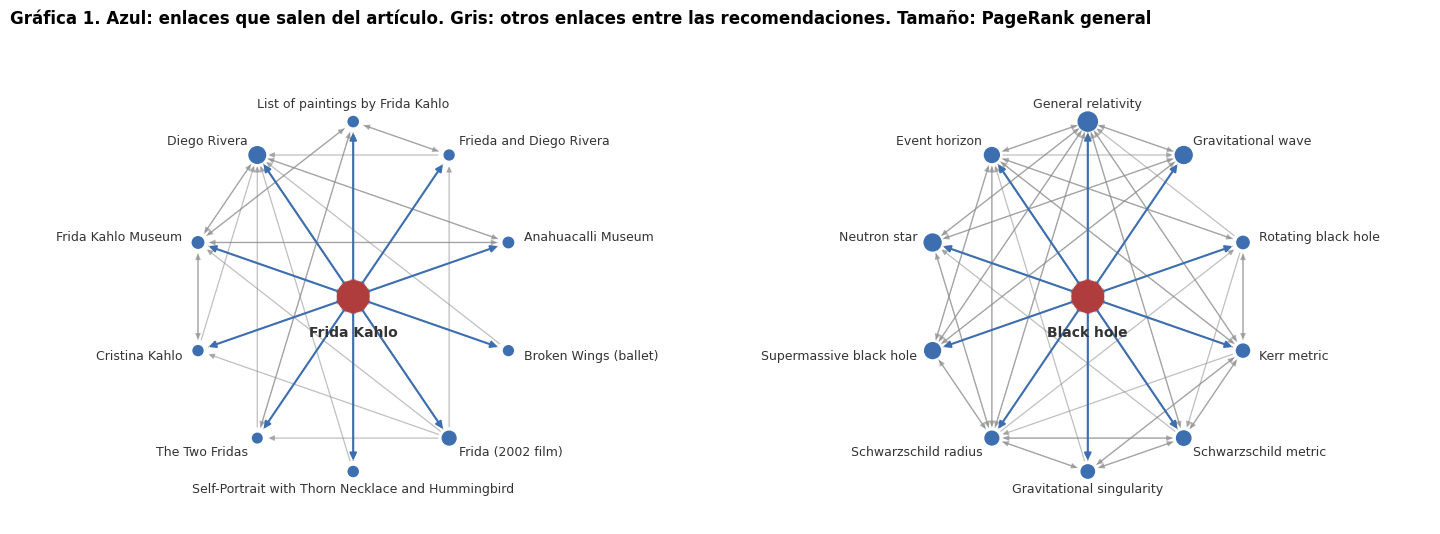

In [6]:
# Gráfica 1. Un artículo y sus recomendaciones, con los enlaces reales entre ellos
def dibujar_recomendaciones(ax, titulo):
    tabla, datos = resultados[titulo]
    s, top = datos["indice"], datos["top"]
    grupo = np.r_[s, top]
    sub = A_an[grupo][:, grupo].toarray()
    G = nx.from_numpy_array(sub, create_using=nx.DiGraph)
    angulos = np.linspace(0, 2 * np.pi, len(top), endpoint=False) + np.pi / 2
    posiciones = {0: (0, 0)} | {i + 1: (np.cos(a), np.sin(a)) for i, a in enumerate(angulos)}
    desde_s = [(u, v) for u, v in G.edges if u == 0]
    otros = [(u, v) for u, v in G.edges if u != 0]
    nx.draw_networkx_edges(G, posiciones, ax=ax, edgelist=otros, edge_color=GRIS, alpha=0.55, width=0.9, arrowsize=8, node_size=260)
    nx.draw_networkx_edges(G, posiciones, ax=ax, edgelist=desde_s, edge_color=AZUL, width=1.5, arrowsize=10, node_size=260)
    tamanos = [520] + [40 + 26 * (np.log10(n) - np.log10(lugar_general[i])) ** 1.5 for i in top]
    nx.draw_networkx_nodes(G, posiciones, ax=ax, node_color=[ROJO] + [AZUL] * len(top), node_size=tamanos)
    ax.text(0, -0.17, titulo, ha="center", va="top", fontweight="bold", color=TINTA, fontsize=10)
    for i, a in enumerate(angulos):
        ax.text(1.1 * np.cos(a), 1.1 * np.sin(a), titulos[top[i]][:50], ha="left" if np.cos(a) > 0.05 else "right" if np.cos(a) < -0.05 else "center",
                va="center", fontsize=9, color=TINTA)
    ax.set_xlim(-2.1, 2.1)
    ax.set_ylim(-1.3, 1.3)
    ax.axis("off")
    return sub

fig, ejes = plt.subplots(1, 2, figsize=(14.5, 5.4))
for ax, titulo in zip(ejes, ["Frida Kahlo", "Black hole"]):
    sub = dibujar_recomendaciones(ax, titulo)
    print(f"{titulo}: {int(sub[0, 1:].sum())} de 10 recomendaciones están enlazadas desde el artículo | {int(sub[1:, 1:].sum())} enlaces entre recomendaciones, de 90 posibles ({sub[1:, 1:].sum() / 90:.0%})")
fig.suptitle("Gráfica 1. Azul: enlaces que salen del artículo. Gris: otros enlaces entre las recomendaciones. Tamaño: PageRank general", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96))
reg.guardar_figura(fig, "grafica_01_grafo_recomendaciones", NB)
plt.show()

**Observaciones.** Las flechas azules confirman lo de la tabla: las 10 recomendaciones de los dos artículos ya están enlazadas desde ellos.

Lo interesante son las líneas grises. En *Black hole*, las recomendaciones se enlazan mucho entre sí: 54 de 90 enlaces posibles (60 %). Forman un grupo compacto de física. En *Frida Kahlo* son 27 de 90 (30 %), y varias conexiones pasan por *Diego Rivera* y los museos. El tamaño muestra el PageRank general: *General relativity* es un nodo grande, mientras que *List of paintings by Frida Kahlo* es muy pequeño y aun así es la primera recomendación.

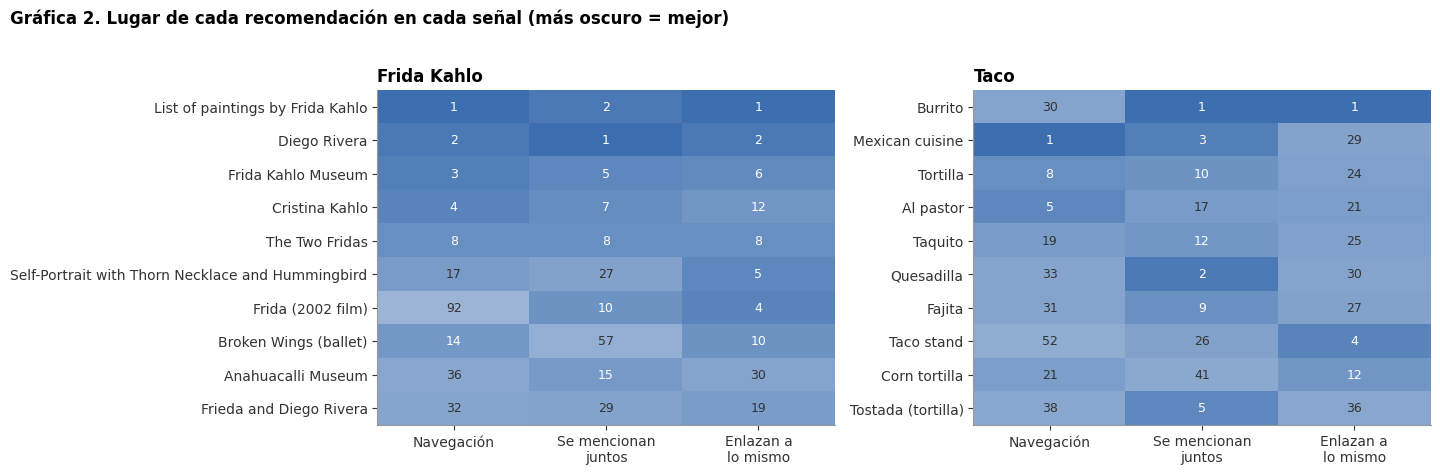

In [7]:
# Gráfica 2. Por qué sale cada recomendación: su lugar en cada señal
fig, ejes = plt.subplots(1, 2, figsize=(14.5, 4.8))
for ax, titulo in zip(ejes, ["Frida Kahlo", "Taco"]):
    tabla = resultados[titulo][0]
    datos = tabla[["navegación", "juntos", "destinos"]].to_numpy()
    im = ax.imshow(datos, cmap=LinearSegmentedColormap.from_list("lugar", [AZUL, "#FFFFFF"]), norm=LogNorm(vmin=1, vmax=10_000), aspect="auto")
    ax.set_xticks(range(3), labels=["Navegación", "Se mencionan\njuntos", "Enlazan a\nlo mismo"])
    ax.set_yticks(range(len(tabla)), labels=[t[:50] for t in tabla["artículo"]])
    for f in range(datos.shape[0]):
        for col in range(3):
            valor = datos[f, col]
            ax.text(col, f, f"{valor:,.0f}" if np.isfinite(valor) else "—", ha="center", va="center", fontsize=9,
                    color="white" if valor <= 15 else TINTA)
    estilo_ejes(ax, titulo, rejilla=None)
fig.suptitle("Gráfica 2. Lugar de cada recomendación en cada señal (más oscuro = mejor)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96))
reg.guardar_figura(fig, "grafica_02_lugar_por_senal", NB)
plt.show()

**Observaciones.** Aquí se ve por qué conviene combinar. En los primeros de *Frida Kahlo* las tres señales coinciden (*Diego Rivera*: 2, 1 y 2). Más abajo se compensan: *Frida (2002 film)* está en el lugar 92 en navegación, pero en el 10 y el 4 en las otras.

En *Taco* pasa más claro: *Burrito* está en el lugar 30 en navegación y primero en las otras dos, y *Mexican cuisine* es primero en navegación y 29 en enlazar a lo mismo. Con una sola señal, alguno de los dos quedaría más abajo. Las 20 recomendaciones de la gráfica están dentro de los primeros 100 lugares en las tres señales.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · RESULTADOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Un artículo visto por cada algoritmo</span></div>

Para terminar de ver la diferencia entre los algoritmos, buscamos un mismo artículo en cada lista.

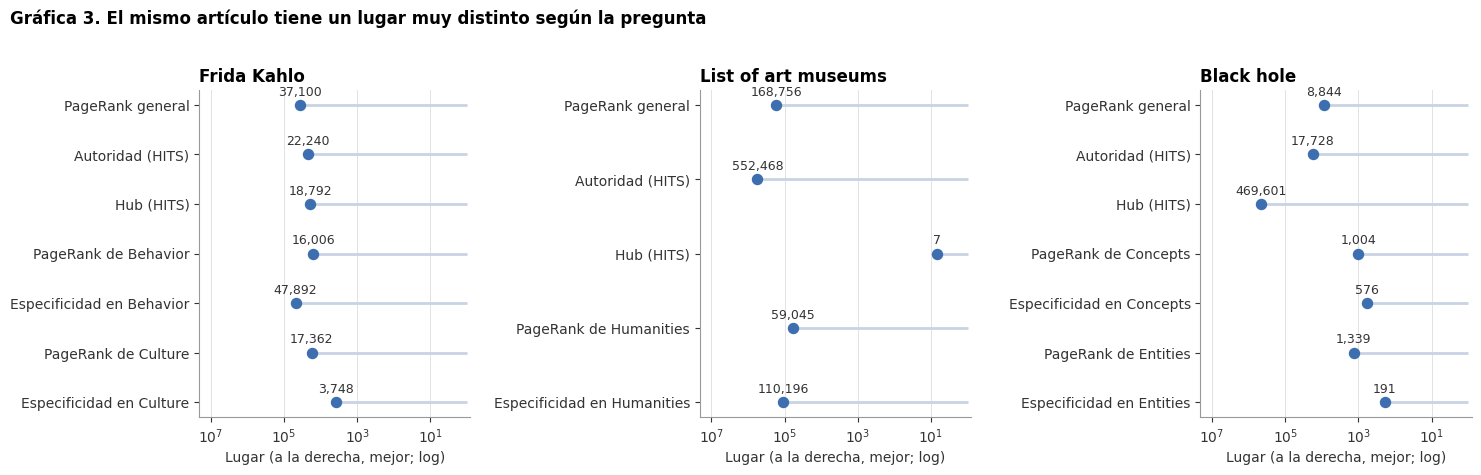

artículo,Frida Kahlo,List of art museums,Black hole
PageRank general,37100.0,168756.0,8844.0
Autoridad (HITS),22240.0,552468.0,17728.0
Hub (HITS),18792.0,7.0,469601.0
PageRank de Behavior,16006.0,NaN,NaN
Especificidad en Behavior,47892.0,NaN,NaN
PageRank de Culture,17362.0,NaN,NaN
Especificidad en Culture,3748.0,NaN,NaN
PageRank de Humanities,NaN,59045.0,NaN
Especificidad en Humanities,NaN,110196.0,NaN
PageRank de Concepts,NaN,NaN,1004.0


WindowsPath('C:/Users/PC/Documents/IIMAS/Datos Masivos II/Práctica 3/T3_DMII/Wikipedia/data/resultados/04_recomendaciones/04_un_articulo_por_algoritmo.csv')

In [8]:
# Gráfica 3. Lugar del mismo artículo con cada algoritmo
pertenencia_txt = pd.read_parquet(TOPICOS_DIR / "02_pertenencia.parquet", columns=["topicos"])["topicos"].to_numpy()
lugar_hub = pd.Series(puntajes["hub"]).rank(ascending=False, method="min").astype(int).to_numpy()
lugar_aut = pd.Series(puntajes["autoridad"]).rank(ascending=False, method="min").astype(int).to_numpy()
ARTICULOS_VISTA = ["Frida Kahlo", "List of art museums", "Black hole"]
filas_vista, temas_vista = [], {}
for titulo in ARTICULOS_VISTA:
    i = int(posicion_titulo[titulo])
    temas = [t for t in pertenencia_txt[i].split("; ") if t][:2]
    temas_vista[titulo] = temas
    fila = {"artículo": titulo, "PageRank general": lugar_general[i], "Autoridad (HITS)": lugar_aut[i], "Hub (HITS)": lugar_hub[i]}
    for t in temas:
        vector = pq.read_table(TOPICOS_DIR / "03_pagerank_por_topico.parquet", columns=[t]).column(0).to_numpy()
        especifico = vector * np.log(np.maximum(vector, 1e-300) / pr_general)
        fila[f"PageRank de {t}"] = int((vector > vector[i]).sum()) + 1
        fila[f"Especificidad en {t}"] = int((especifico > especifico[i]).sum()) + 1
        del vector, especifico
    filas_vista.append(fila)
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True)
for ax, fila in zip(ejes, filas_vista):
    claves = [k for k in fila if k != "artículo"][::-1]
    valores = [fila[k] for k in claves]
    ax.hlines(claves, 1, valores, color="#C9D3E3", linewidth=2)
    ax.scatter(valores, claves, s=52, color=AZUL, zorder=3)
    for valor, clave in zip(valores, claves):
        ax.annotate(f"{valor:,}", (valor, clave), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=9, color=TINTA)
    ax.set_xscale("log")
    ax.set_xlim(0.8, n * 3)
    ax.invert_xaxis()
    estilo_ejes(ax, fila["artículo"], "Lugar (a la derecha, mejor; log)", rejilla="x")
fig.suptitle("Gráfica 3. El mismo artículo tiene un lugar muy distinto según la pregunta", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96))
reg.guardar_figura(fig, "grafica_03_un_articulo_por_algoritmo", NB)
plt.show()
tabla_vista = pd.DataFrame(filas_vista).set_index("artículo").T
display(tabla_vista)
reg.guardar_tabla(tabla_vista, "04_un_articulo_por_algoritmo", NB)

**Observaciones.** El mismo artículo cambia mucho según la pregunta. *List of art museums* es el hub número 7 de toda Wikipedia, pero está en el lugar 168,756 de PageRank y en el 552,468 como autoridad: como destino pesa poco, pero reúne muchos enlaces buenos. *Black hole* es lo contrario: está en el lugar 8,844 de PageRank, 17,728 como autoridad y 469,601 como hub.

En PageRank por tema, *Black hole* sube del lugar 8,844 al 191 con especificidad en *Entities*. *Frida Kahlo* sube del 37,100 al 3,748 en *Culture*, pero baja al 47,892 en *Behavior*. Estos son los dos primeros temas de cada artículo en orden alfabético, y muestran que un tema asignado por categorías no siempre describe bien el artículo.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · VALIDACIÓN</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. ¿Qué tan buenas son las recomendaciones?</span></div>

No hay clics para medir si a un lector le sirven. Usamos dos medidas indirectas sobre 50 artículos elegidos al azar (semilla 42), con entre 20 y 300 enlaces de salida y al menos 5 de entrada.

**Enlaces recuperados.** Ocultamos el 20 % de los enlaces de salida del artículo y pedimos 10 recomendaciones usando el resto. Medimos qué parte de los enlaces ocultos aparece:

$$\text{recuperados@10} = \frac{|\text{recomendados} \cap \text{ocultos}|}{|\text{ocultos}|}$$

Esta medida favorece lo que los editores ya enlazaron, y castiga una buena recomendación que todavía nadie enlazó. Con 10 recomendaciones y un artículo con muchos enlaces ocultos, además, no puede llegar a 100 %.

**Comparten categoría.** Qué parte de las recomendaciones tiene al menos una categoría en común con el artículo. Es independiente de los enlaces, porque las categorías no se usan para recomendar. Quitamos categorías administrativas y las de nacimientos y muertes por año.

**Del núcleo general.** Qué parte de las recomendaciones está entre los 1,000 primeros de PageRank. Sirve para ver si un método recomienda lo mismo a todos.

Comparamos contra el PageRank general (recomendar siempre lo más importante) y contra cada señal por separado. Los intervalos de confianza de 95 % se calculan con remuestreo (*bootstrap*).

50 artículos en 24.3 min


,recuperados@10,recuperados: IC bajo,recuperados: IC alto,comparten categoría,categoría: IC bajo,categoría: IC alto,"del top-1,000 general"
PageRank general,1.3%,0.4%,2.6%,0.0%,0.0%,0.0%,100.0%
Navegación sin especificidad,12.0%,7.1%,17.7%,3.8%,1.6%,6.6%,61.8%
Navegación,15.0%,10.1%,20.9%,13.8%,9.6%,18.4%,12.6%
Se mencionan juntos,5.1%,2.6%,8.2%,45.6%,36.6%,54.2%,0.0%
Enlazan a lo mismo,3.8%,1.6%,6.6%,48.2%,39.0%,57.4%,0.0%
Combinación,8.2%,5.2%,11.9%,54.2%,44.8%,63.2%,0.0%


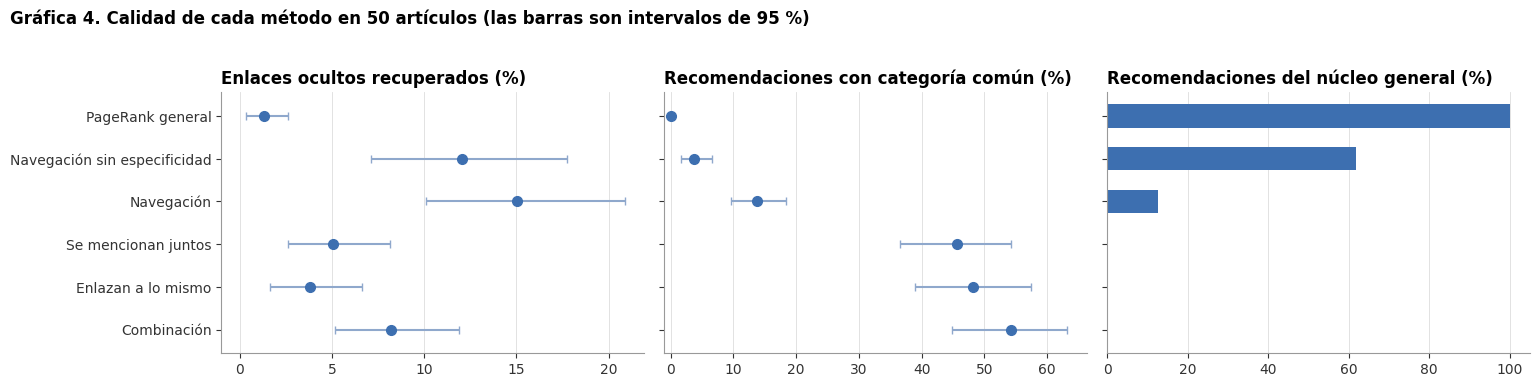

In [9]:
# Evaluación con 50 artículos al azar: se oculta el 20 % de sus enlaces de salida
inicio = time.time()
rng = np.random.default_rng(42)
muestra = rng.choice(np.where((k_out >= 20) & (k_out <= 300) & (k_in >= 5))[0], 50, replace=False)
METODOS = ["PageRank general", "Navegación sin especificidad", "Navegación", "Se mencionan juntos", "Enlazan a lo mismo", "Combinación"]
recuperados = {m: [] for m in METODOS}
elegidos = []
t0 = time.perf_counter()
for s in muestra:
    salientes = A_an[s].indices.copy()
    rng.shuffle(salientes)
    corte = max(1, len(salientes) // 5)
    ocultos, visibles = set(salientes[:corte].tolist()), salientes[corte:]
    excluir = np.r_[s, visibles]
    p, _ = pagerank_articulo(s, visibles=visibles)
    l_nav = lugares(senal_navegacion(p), excluir)
    l_jun = lugares(senal_juntos(s), excluir)
    l_des = lugares(senal_destinos(visibles), excluir)
    listas_m = {"PageRank general": lugares(pr_general, excluir), "Navegación sin especificidad": lugares(p, excluir), "Navegación": l_nav,
                "Se mencionan juntos": l_jun, "Enlazan a lo mismo": l_des}
    final = combinar(l_nav, l_jun, l_des)
    for m in METODOS:
        puntaje = final if m == "Combinación" else 1 / listas_m[m]
        top = primeros(puntaje, K_RECOMENDACIONES)
        recuperados[m].append(len(ocultos & set(top.tolist())) / len(ocultos))
        elegidos.append((int(s), m, top))
print(f"{len(muestra)} artículos en {(time.perf_counter() - t0) / 60:.1f} min")

ids = nodos_an["id"].to_numpy()
necesarios = set()
for s, _, top in elegidos:
    necesarios.update(ids[top].tolist())
    necesarios.add(int(ids[s]))
cats = ds.dataset(GRAFO / "categorias_nodo").to_table(filter=ds.field("id").isin(list(necesarios))).to_pandas()
ADMINISTRATIVAS = re.compile(r"^(Wikipedia|Articles?\b|All articles|Pages?\b|CS1|Webarchive|Use |Short description|Commons|Hidden categories|Tracking categories|"
                             r"Container categories|Template|Redirects?\b|User |Stub|Good articles|Featured |Coordinates|Accuracy disputes|Orphaned|Dead |AC with|Noindexed|"
                             r"Infobox|Official website|Disambiguation|Living people|Taxonomy|\d{3,4}s? (births|deaths)|Year of)", re.IGNORECASE)
cats = cats[~cats["category"].str.match(ADMINISTRATIVAS)]
categorias_de = cats.groupby("id")["category"].apply(set).to_dict()
comparten = {m: [] for m in METODOS}
nucleo = {m: [] for m in METODOS}
for s, m, top in elegidos:
    propias = categorias_de.get(int(ids[s]), set())
    if propias:
        comparten[m].append(np.mean([len(propias & categorias_de.get(int(ids[j]), set())) > 0 for j in top]))
    nucleo[m].append(np.mean(lugar_general[top] <= 1000))


def media_ic(valores):
    """Media e intervalo de confianza de 95 % por bootstrap."""
    valores = np.asarray(valores)
    remuestras = rng.choice(valores, (5000, len(valores))).mean(axis=1)
    return valores.mean(), np.percentile(remuestras, 2.5), np.percentile(remuestras, 97.5)


evaluacion = pd.DataFrame({m: {"recuperados@10": media_ic(recuperados[m])[0], "recuperados: IC bajo": media_ic(recuperados[m])[1], "recuperados: IC alto": media_ic(recuperados[m])[2],
                               "comparten categoría": media_ic(comparten[m])[0], "categoría: IC bajo": media_ic(comparten[m])[1], "categoría: IC alto": media_ic(comparten[m])[2],
                               "del top-1,000 general": np.mean(nucleo[m])} for m in METODOS}).T
display(evaluacion.style.format("{:.1%}"))

# Gráfica 4. Calidad de cada método
fig, ejes = plt.subplots(1, 3, figsize=(15.5, 3.9), sharey=True)
y = np.arange(len(METODOS))[::-1]
for ax, base, bajo, alto, nombre in [(ejes[0], "recuperados@10", "recuperados: IC bajo", "recuperados: IC alto", "Enlaces ocultos recuperados (%)"),
                                     (ejes[1], "comparten categoría", "categoría: IC bajo", "categoría: IC alto", "Recomendaciones con categoría común (%)")]:
    valores = 100 * evaluacion[base].to_numpy()
    ax.errorbar(valores, y, xerr=[valores - 100 * evaluacion[bajo].to_numpy(), 100 * evaluacion[alto].to_numpy() - valores], fmt="o", color=AZUL, ecolor="#8FA8CC", capsize=3, markersize=7)
    estilo_ejes(ax, nombre, rejilla="x")
    ax.title.set_fontsize(10)
    ax.set_xlim(left=-1)
ejes[0].set_yticks(y, labels=METODOS)
ejes[2].barh(y, 100 * evaluacion["del top-1,000 general"], color=AZUL, height=0.55)
estilo_ejes(ejes[2], "Recomendaciones del núcleo general (%)", rejilla="x")
ejes[2].title.set_fontsize(10)
fig.suptitle("Gráfica 4. Calidad de cada método en 50 artículos (las barras son intervalos de 95 %)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.95))
archivo_g4 = reg.guardar_figura(fig, "grafica_04_evaluacion", NB)
plt.show()
reg.registrar_paso("04.4", inicio, [reg.guardar_tabla(evaluacion, "05_evaluacion", NB), archivo_g4],
                   f"combinación: {evaluacion.loc['Combinación', 'recuperados@10']:.1%} recuperados, {evaluacion.loc['Combinación', 'comparten categoría']:.1%} comparten categoría")
POOL.shutdown()

**Observaciones.** Ningún método gana en todo. La navegación recupera más enlaces ocultos (15.0 %, intervalo de 10.1 a 20.9). La combinación recupera menos (8.2 %, de 5.2 a 11.9), pero es la mejor en categoría común (54.2 %, de 44.8 a 63.2).

Una posible razón está en la tercera gráfica. Los enlaces ocultos pueden ser artículos generales, como un país, y la navegación todavía recomienda algunos: el 12.6 % de sus recomendaciones está en el top-1,000. La combinación y las otras dos señales no recomiendan ninguno. Sin especificidad, ese porcentaje sube a 61.8 %. El PageRank general, que recomienda lo mismo a todos, recupera solo 1.3 % y nunca comparte categoría.

Elegimos la combinación porque buscamos recomendaciones cercanas al artículo, y aceptamos que no gane en la primera medida. Con 50 artículos los intervalos son amplios: la combinación no se distingue claramente de las señales 2 y 3 en categoría común, ni la especificidad de la navegación sin ajustar en enlaces recuperados.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · CIERRE</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Conclusiones y limitaciones</span></div>

### Qué responde cada método

| Pregunta | Método | Resultado |
|---|---|---|
| ¿A qué artículos se llega más siguiendo enlaces? | PageRank | *United States*, *The New York Times*, *World War II* |
| ¿Qué páginas reúnen y a cuáles se apunta? | HITS | Hubs: 85 de 100 son listas o cronologías. Autoridades: el núcleo general |
| ¿Qué es lo propio de un tema? | PageRank por tema con especificidad | Pureza mediana del top-100: de 17 % a 49 % |
| ¿Cómo está organizado un tema? | HITS dentro del tema | *Food and drink*: páginas de cocina que enlazan a ingredientes |
| ¿Qué leer después de este artículo? | Tres señales combinadas | 54.2 % comparte categoría con el artículo, y ninguna recomendación está en el top-1,000 |

### Lo que encontramos

1. **Un enlace no vale lo mismo que otro.** *Season (sports)* tiene 6.4 veces más enlaces que *Open access*, y queda 2,336 lugares abajo.
2. **Hay un núcleo general que aparece en casi todo.** En una parte son temas que se mencionan en el texto, como los países. En otra son fuentes citadas: el 64 % de los enlaces a *The New York Times* solo está en referencias, según una muestra.
3. **HITS distingue los dos papeles sin saber qué es una lista.** Sobre toda Wikipedia se queda en el núcleo general. Dentro de un tema se entiende mejor, aunque se queda con la parte más densa, como la astronomía en *Science*.
4. **Ordenar por lo que un tema sube ayuda más que el puntaje solo.** En *Food and drink*, el top-100 pasa de 11 % a 81 % de pureza. Falla en temas muy amplios, como *Humans*.
5. **Para adivinar el tema, los vecinos ganan.** El voto de vecinos acierta 48.3 %, contra 39.2 % del puntaje por tema.
6. **Las recomendaciones casi siempre ordenan enlaces que ya existen.** De 120, 116 ya estaban enlazadas desde el artículo.

### Para qué podría servir

Son ideas, no resultados. Ninguna se probó con lectores.

- **Lectores:** destacar pocos enlaces en artículos que tienen cientos, en lugar de agregar enlaces nuevos.
- **Editores de un tema:** usar la lista por especificidad y los hubs como punto de partida para revisar un tema.
- **Mantenimiento:** corregir enlaces que apuntan a desambiguaciones, como los 457 que llegan a *State*.
- **Artículos sin tema:** sugerir un tema con el voto de vecinos para que una persona lo confirme. Con 48.3 % de aciertos no alcanza para hacerlo de forma automática.

### Limitaciones

- **Solo hay enlaces.** No usamos texto, visitas ni clics, así que no sabemos si a un lector le sirve una recomendación.
- **Un enlace es un enlace.** El grafo no separa el texto de las referencias, y no incluye los enlaces que agregan las plantillas al expandirse. La medición de referencias es aproximada y viene de una muestra.
- **Los temas dependen de las categorías.** Hay errores, como *Saint Philip, Antigua and Barbuda* en *Food and drink*, y omisiones, como *Immanuel Kant* fuera de *Philosophy*.
- **La evaluación de recomendaciones usa 50 artículos.** Los intervalos son amplios, y la medida de enlaces recuperados premia lo que los editores ya enlazaron.
- **Refleja a la Wikipedia en inglés.** Por eso hay tanto de Estados Unidos: censos, medios y estados están entre las primeras autoridades.
- **No sirve todavía en tiempo real.** Unos 27 segundos por artículo equivalen a casi 6 años de cómputo seguido para los 6.88 millones, así que un servicio real necesitaría un método aproximado o limitarse a los artículos que más se consultan.

### Qué seguiría

- Quitar del grafo los enlaces que solo están en referencias y ver cómo cambian los resultados.
- Evaluar las recomendaciones con los datos públicos de navegación que publica Wikimedia (*clickstream*), que sí registran por dónde pasan los lectores.
- Probar listas balanceadas para lectores con varios intereses.